# EDA: pharmacy demand and expiry-risk data

**Questions**
1. Is the synthetic dataset clean and internally consistent?
2. What demand patterns (trend, seasonality, weekday, category, zero days) should the forecast capture?
3. How much independent support exists for expiry-risk labels in each chronological split?
4. Which fields would leak future information, and how are they kept out?

**Scope.** Descriptive statistics use the full history because they involve no labels.
Any feature–target relationship is examined on the **training split only**, so validation
and test data never influence feature or model choices.

**Prerequisite** (from the repository root):
`python src/data_generator.py` then `python -m src.features --report reports/day3-splits.json`.

In [1]:
# Setup: paths, imports and fixed configuration
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_quality import validate_dataset
from src.features import DEMAND_FEATURES, EXPIRY_FEATURES
from src.splits import TEST_START, VALID_START

DATA = ROOT / "data"
manifest = json.loads((DATA / "manifest.json").read_text())
tables = {n: pd.read_csv(DATA / f"{n}.csv") for n in
          ["products", "batches", "sales", "daily_sales", "inventory_snapshots"]}
demand = pd.read_csv(DATA / "demand_features.csv")
expiry = pd.read_csv(DATA / "expiry_features.csv")
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 90})
{k: manifest[k] for k in ["seed", "products", "days", "start_date", "schema_version"]}

{'seed': 42,
 'products': 80,
 'days': 730,
 'start_date': '2022-01-01',
 'schema_version': 2}

## 1. Data quality

In [2]:
report = validate_dataset(tables)  # raises on any broken key, balance, date or label
print("checks passed:", report["checks_passed"])
pd.DataFrame({"rows": {n: len(t) for n, t in tables.items()},
              "missing values": {n: int(t.isna().sum().sum()) for n, t in tables.items()}})

checks passed: True


,rows,missing values
products,80,0
batches,2003,1102
sales,59281,0
daily_sales,58400,0
inventory_snapshots,39062,0


Missing values are expected **only** in `batches.outcome_date` / `expiry_risk` for
batches whose outcome is still unknown at the end of history (censored). They are not
imputed: an unknown outcome is not a safe (negative) outcome.

In [3]:
daily = tables["daily_sales"].assign(date=lambda d: pd.to_datetime(d.date))
per_product = daily.groupby("product_id").quantity_sold
outliers = (daily.quantity_sold > per_product.transform("mean") + 4 * per_product.transform("std"))
print(f"product-days with sales > mean + 4 SD of that product: {int(outliers.sum())} of {len(daily):,}")
print(f"zero-sales product-days: {report['zero_sales_product_days']}, "
      f"stockout product-days: {report['stockout_product_days']}")
daily.quantity_sold.describe().round(1).to_frame().T

product-days with sales > mean + 4 SD of that product: 16 of 58,400
zero-sales product-days: 31, stockout product-days: 0


,count,mean,std,min,25%,50%,75%,max
quantity_sold,58400.0,21.0,14.3,0.0,10.0,17.0,29.0,96.0


- Daily sales follow product-level Poisson demand, so extreme values are rare and genuine;
  no outlier removal or capping is applied.
- **Stockout limitation:** restocking is immediate, so recorded sales equal demand here.
  Real pharmacy sales are censored by stockouts; this demo cannot measure that effect.
  `unmet_demand` is a simulator diagnostic and never a feature.

## 2. Demand patterns

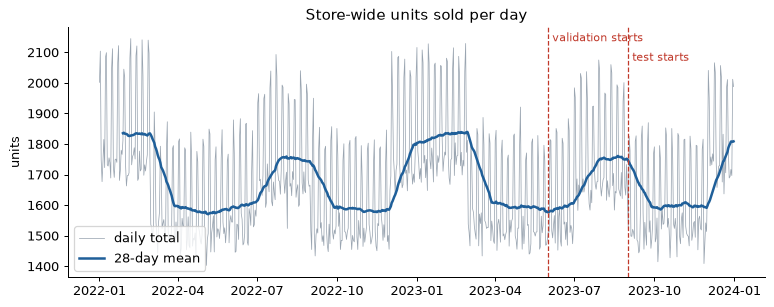

In [4]:
fig, ax = plt.subplots()
store = daily.groupby("date").quantity_sold.sum()
ax.plot(store.index, store, lw=0.6, color="#9aa5b1", label="daily total")
ax.plot(store.index, store.rolling(28).mean(), lw=2, color="#1f5f99", label="28-day mean")
for boundary, name, y in [(VALID_START, "validation", 0.98), (TEST_START, "test", 0.90)]:
    ax.axvline(pd.Timestamp(boundary), color="#c0392b", ls="--", lw=1)
    ax.text(pd.Timestamp(boundary), y, f" {name} starts", color="#c0392b", va="top",
            fontsize=9, transform=ax.get_xaxis_transform())
ax.set(title="Store-wide units sold per day", ylabel="units"); ax.legend(loc="lower left")
plt.show()

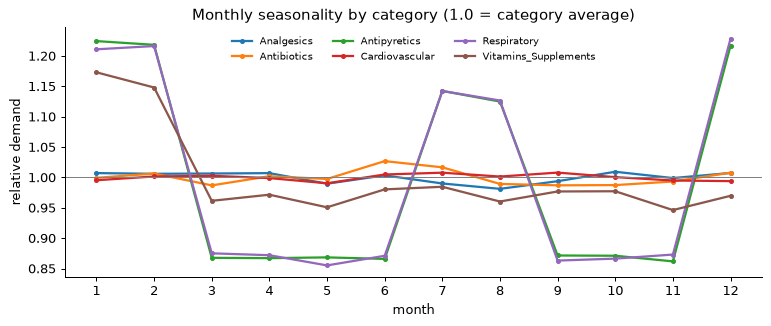

In [5]:
by_cat = (daily.merge(tables["products"][["product_id", "category"]])
          .assign(month=lambda d: d.date.dt.month)
          .groupby(["category", "month"]).quantity_sold.mean().unstack(0))
index = by_cat / by_cat.mean()  # each category relative to its own average
fig, ax = plt.subplots()
index.plot(ax=ax, lw=1.8, marker="o", ms=3)
ax.axhline(1, color="grey", lw=0.8)
ax.set(title="Monthly seasonality by category (1.0 = category average)",
       xlabel="month", ylabel="relative demand", xticks=range(1, 13))
ax.legend(ncol=3, fontsize=8, frameon=False); plt.show()

In [6]:
weekday = daily.groupby(daily.date.dt.day_name()).quantity_sold.mean()
weekday = weekday.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
(weekday / weekday.mean()).round(3).to_frame("relative demand").T

date,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
relative demand,0.947,0.946,0.946,0.947,0.943,1.136,1.135


- Respiratory and antipyretic products rise in winter (Dec–Feb) and the monsoon (Jul–Aug);
  vitamins rise in Jan–Feb; other categories are flat.
- Weekends run about 20% above weekdays.
- Because every 30-day target spans four full weeks, the weekday effect mostly averages out;
  month/season and product velocity matter more. Features therefore include recent rolling
  sales, the same window last year (available after one year), month and category.

## 3. Forecast target and features (training split only)

training origins: 62 Sundays x 80 products


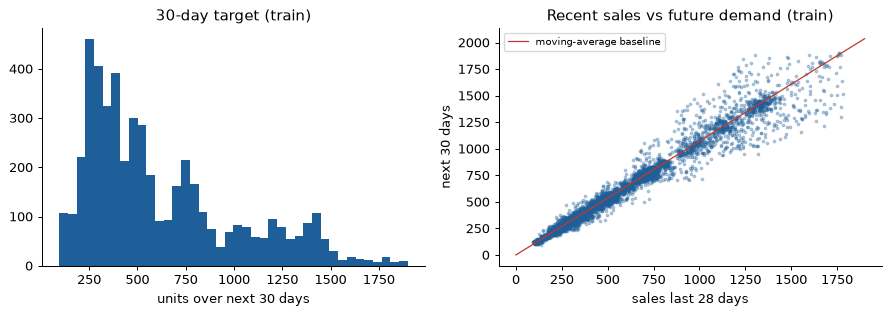

In [7]:
train = demand[demand.split == "train"]
print(f"training origins: {train.origin_date.nunique()} Sundays x {train.product_id.nunique()} products")
fig, axes = plt.subplots(1, 2)
axes[0].hist(train.target_30d, bins=40, color="#1f5f99")
axes[0].set(title="30-day target (train)", xlabel="units over next 30 days")
axes[1].scatter(train.sales_28d, train.target_30d, s=4, alpha=0.3, color="#1f5f99")
lim = [0, train[["sales_28d", "target_30d"]].max().max()]
axes[1].plot(lim, [l * 30 / 28 for l in lim], color="#c0392b", lw=1, label="moving-average baseline")
axes[1].set(title="Recent sales vs future demand (train)", xlabel="sales last 28 days",
            ylabel="next 30 days"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
numeric = [c for c in DEMAND_FEATURES if c not in ("category",)]
(train[numeric + ["target_30d"]].corr(method="spearman")["target_30d"]
 .drop("target_30d").sort_values(ascending=False).round(3).to_frame("Spearman vs target (train)"))

,Spearman vs target (train)
sales_same_window_last_year,0.993
mean_28d,0.987
sales_28d,0.987
sales_14d,0.985
sales_56d,0.985
sales_7d,0.980
std_28d,0.917
on_hand_units,0.548
typical_shelf_life_days,0.396
week_of_year,0.002


- Recent sales almost determine the 30-day total; a 28-day moving average scaled to 30 days
  is a strong, honest baseline that candidate models must beat.
- `sales_same_window_last_year` is missing for origins in the first year (71% of training
  rows), so its correlation uses only the later origins. Linear models need imputation
  fitted on training data; tree models can use missingness directly.
- Spearman correlations are diagnostics for feature design, not a selection rule.

## 4. Expiry-risk labels and support

outcome_status
sold_out    982
censored    551
expired     470


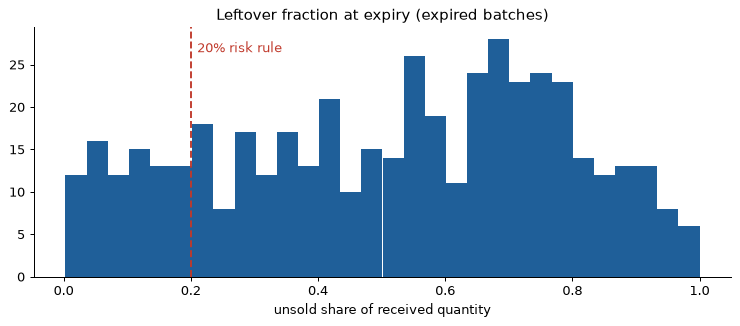

In [9]:
batches = tables["batches"]
expired = batches[batches.outcome_status == "expired"]
leftover = expired.quantity_remaining / expired.quantity_received
print(batches.outcome_status.value_counts().to_string())
fig, ax = plt.subplots()
ax.hist(leftover, bins=30, color="#1f5f99")
ax.axvline(0.2, color="#c0392b", ls="--"); ax.text(0.21, ax.get_ylim()[1] * 0.9, "20% risk rule", color="#c0392b")
ax.set(title="Leftover fraction at expiry (expired batches)", xlabel="unsold share of received quantity")
plt.show()

In [10]:
support = (expiry.assign(label=expiry.expiry_risk.map({1: "positive", 0: "negative"}).fillna("unknown"))
             .pivot_table(index="split", columns="label", values="batch_id", aggfunc="nunique", fill_value=0)
             .reindex(["train", "validation", "test", "excluded"]))
support["positive rate"] = (support.positive / (support.positive + support.negative)).round(2)
support

label,negative,positive,unknown,positive rate
split,,,,
train,157,236,0,0.60
validation,29,25,0,0.46
test,32,71,0,0.69
excluded,47,57,32,0.55


- Each row is **one batch** (its first Sunday snapshot within 60 days of expiry), so the counts
  are independent batches, not repeated weekly snapshots.
- Validation has only 54 labelled batches (25 positive). Threshold choice will be noisy;
  report confidence intervals and avoid broad hyperparameter searches.
- Positive rates (≈45–70%) reflect deliberate stress scenarios (short-dated and oversized
  deliveries), not real pharmacy prevalence. Excluded rows have unknown outcomes, outcomes
  that resolve after the next split boundary, or fewer than 28 days of sales history.

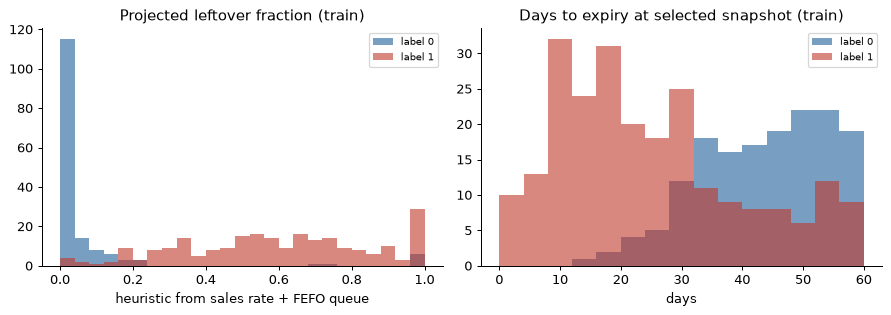

rule alert,0,1
observed,,
0.0,146,11
1.0,18,218


In [11]:
tr = expiry[expiry.split == "train"]
fig, axes = plt.subplots(1, 2)
for label, colour in [(0, "#1f5f99"), (1, "#c0392b")]:
    rows = tr[tr.expiry_risk == label]
    axes[0].hist(rows.projected_leftover_fraction.clip(upper=1.0), bins=np.linspace(0, 1, 26),
                 alpha=0.6, color=colour, label=f"label {label}")
    axes[1].hist(rows.days_to_expiry, bins=np.arange(0, 64, 4), alpha=0.6, color=colour,
                 label=f"label {label}")
axes[0].set(title="Projected leftover fraction (train)", xlabel="heuristic from sales rate + FEFO queue")
axes[1].set(title="Days to expiry at selected snapshot (train)", xlabel="days")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
rule = (tr.projected_leftover_fraction > 0.2).astype(int)
pd.crosstab(tr.expiry_risk, rule, rownames=["observed"], colnames=["rule alert"])

- The transparent rule (*alert if projected leftover > 20% of received units*) separates the
  classes on training data but not perfectly: later short-dated deliveries can jump ahead in
  FEFO order and demand varies. This is the expiry baseline; candidate classifiers must beat
  it on validation before the test set is opened.
- Many positives are first seen fewer than 30 days before expiry: these are short-dated
  deliveries whose first snapshot comes soon after receipt. That separation is partly a
  property of the stress scenario, so `days_to_expiry` may look more predictive here than
  it would in a real pharmacy.
- The crosstab above is training data only; no validation or test outcome has been inspected.

## 5. Leakage analysis

In [12]:
pd.DataFrame([
    ("products.base_daily_demand", "simulator latent parameter", "excluded"),
    ("daily_sales.simulated_demand / unmet_demand", "oracle diagnostics", "excluded"),
    ("batches.quantity_remaining", "final balance after all future sales", "excluded; snapshot stock used"),
    ("batches.outcome_status / outcome_date / expiry_risk", "future outcome", "labels only"),
    ("sales after the origin", "future", "rolling windows end at the origin"),
    ("30-day targets crossing a boundary", "overlaps next period", "origin excluded"),
    ("outcomes resolved after a boundary", "label not yet known", "batch excluded"),
], columns=["field / risk", "why it leaks", "treatment"])

,field / risk,why it leaks,treatment
0,products.base_daily_demand,simulator latent parameter,excluded
1,daily_sales.simulated_demand / unmet_demand,oracle diagnostics,excluded
2,batches.quantity_remaining,final balance after all future sales,excluded; snapshot stock used
3,batches.outcome_status / outcome_date / expiry...,future outcome,labels only
4,sales after the origin,future,rolling windows end at the origin
5,30-day targets crossing a boundary,overlaps next period,origin excluded
6,outcomes resolved after a boundary,label not yet known,batch excluded


In [13]:
forbidden = {"base_daily_demand", "simulated_demand", "unmet_demand", "outcome_status",
             "outcome_date", "expiry_risk", "target_30d"}
print("forbidden fields in demand features:", forbidden & set(DEMAND_FEATURES) or "none")
print("forbidden fields in expiry features:", forbidden & set(EXPIRY_FEATURES) or "none")
print("demand split windows:")
print(demand.groupby("split").origin_date.agg(["min", "max", "count"]).to_string())

forbidden fields in demand features: none
forbidden fields in expiry features: none
demand split windows:
                   min         max  count
split                                    
excluded    2023-05-07  2023-08-27    640
test        2023-09-03  2023-11-26   1040
train       2022-02-27  2023-04-30   4960
validation  2023-06-04  2023-07-30    720


Automated evidence lives in `tests/test_features.py`: features computed on a history
truncated at an origin equal those computed with about four more months of later data.
A one-off check injecting a 1-day future sales shift or the final batch balance made those
tests fail.

## 6. Findings and next steps

- Data passes every integrity check; no imputation or outlier removal is needed beyond the
  documented first-year gap in `sales_same_window_last_year`.
- Demand: compare the 28-day moving-average baseline with a regularised linear model and a
  gradient-boosted tree on identical origins; report MAE, RMSE and WAPE.
- Expiry: compare the projected-leftover rule with logistic regression and a tree model;
  pick the alert threshold on validation, then report precision, recall, F1 and a confusion
  matrix once on test, with bootstrap intervals given the small support.
- All findings describe a synthetic stress-test dataset, not real pharmacy accuracy.